In [2]:
import sys
print(sys.executable)

/Users/user/Desktop/credit-risk-analysis/venv/bin/python


In [3]:
from ucimlrepo import fetch_ucirepo

credit_data = fetch_ucirepo(id=350)

In [4]:
X = credit_data.data.features
y = credit_data.data.targets


In [5]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (30000, 23)
Target shape: (30000, 1)


In [6]:
X.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [7]:
y.head()

,Y
0,1
1,1
2,0
3,0
4,0


# Credit Risk Analytics & Loan Default Prediction

## Stage 2 — Data Understanding

### Business Question

Which customer and credit characteristics are associated with increased default risk, and how can data analytics and machine learning help identify higher-risk customers while maintaining explainability and responsible decision-making?

### Target Variable

The target variable `Y` represents whether a customer defaulted on their credit card payment in the following month:

- `0` = No default
- `1` = Default

The objective of the project is to analyse the factors associated with default and later develop an interpretable model that estimates default risk.

In [8]:
y["Y"].value_counts()

Y
0    23364
1     6636
Name: count, dtype: int64

In [11]:
y["Y"].value_counts(normalize=True) * 100default_counts = y["Y"].value_counts()

print("No Default:", default_counts[0])
print("Default:", default_counts[1])

default_rate = y["Y"].mean() * 100

print(f"Default Rate: {default_rate:.2f}%")

SyntaxError: invalid decimal literal (3126705720.py, line 1)

In [10]:
default_counts = y["Y"].value_counts()

print("No Default:", default_counts[0])
print("Default:", default_counts[1])

default_rate = y["Y"].mean() * 100

print(f"Default Rate: {default_rate:.2f}%")

No Default: 23364
Default: 6636
Default Rate: 22.12%


### Initial Target Observation

The dataset contains 30,000 customers. The target variable is not evenly distributed, with the majority of customers not defaulting in the following month.

Approximately ** [22.12%} ** of customers defaulted.

This class imbalance will need to be considered when evaluating predictive models, as accuracy alone may not provide a complete picture of model performance.

In [12]:
credit_data.variables

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,NaN,NaN,None,no
1,X1,Feature,Integer,NaN,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,NaN,PAY_0,None,no
7,X7,Feature,Integer,NaN,PAY_2,None,no
8,X8,Feature,Integer,NaN,PAY_3,None,no
9,X9,Feature,Integer,NaN,PAY_4,None,no


In [13]:
credit_data.variables[["name", "role", "type", "description"]]

,name,role,type,description
0,ID,ID,Integer,NaN
1,X1,Feature,Integer,LIMIT_BAL
2,X2,Feature,Integer,SEX
3,X3,Feature,Integer,EDUCATION
4,X4,Feature,Integer,MARRIAGE
5,X5,Feature,Integer,AGE
6,X6,Feature,Integer,PAY_0
7,X7,Feature,Integer,PAY_2
8,X8,Feature,Integer,PAY_3
9,X9,Feature,Integer,PAY_4


In [14]:
column_names = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6"
}

X = X.rename(columns=column_names)
y = y.rename(columns={"Y": "DEFAULT"})

In [15]:
X.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [16]:
y.head()

,DEFAULT
0,1
1,1
2,0
3,0
4,0


In [18]:
# Check for missing values
print("Missing values:")
print(X.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", X.duplicated().sum())

# Basic statistical summary
X.describe()

Missing values:
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
dtype: int64

Duplicate rows: 56


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000
mean,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,...,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567
std,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,...,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,...,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000


In [19]:
# Examine categorical variables

categorical_columns = ["SEX", "EDUCATION", "MARRIAGE"]

for column in categorical_columns:
    print(f"\n{column}")
    print(X[column].value_counts().sort_index())


SEX
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [20]:
# Combine features and target for analysis
df = X.copy()
df["DEFAULT"] = y["DEFAULT"]

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [21]:
# Default rate by most recent repayment status

pay0_default = (
    df.groupby("PAY_0")["DEFAULT"]
      .agg(["count", "mean"])
      .reset_index()
)

pay0_default["default_rate_%"] = pay0_default["mean"] * 100

pay0_default

,PAY_0,count,mean,default_rate_%
0,-2,2759,0.132294,13.229431
1,-1,5686,0.167781,16.778051
2,0,14737,0.128113,12.811291
3,1,3688,0.339479,33.947939
4,2,2667,0.691414,69.141357
5,3,322,0.757764,75.776398
6,4,76,0.684211,68.421053
7,5,26,0.500000,50.000000
8,6,11,0.545455,54.545455
9,7,9,0.777778,77.777778


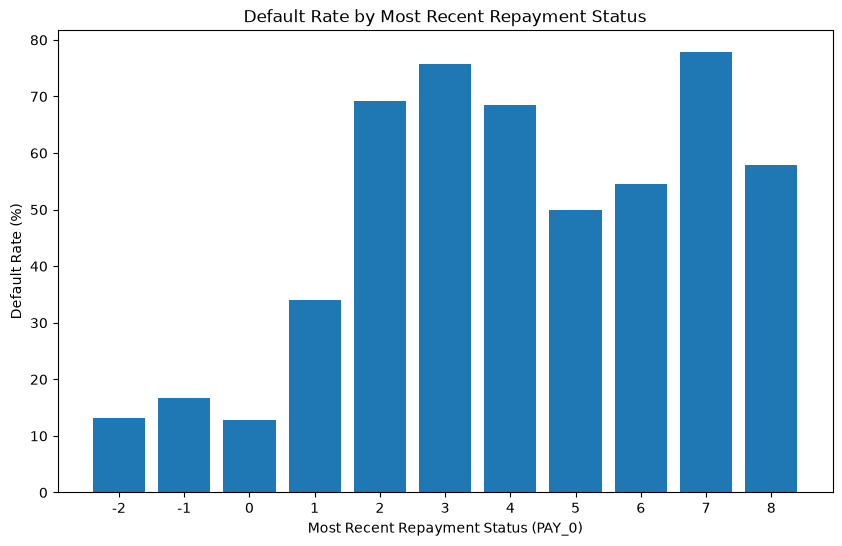

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    pay0_default["PAY_0"].astype(str),
    pay0_default["default_rate_%"]
)

plt.xlabel("Most Recent Repayment Status (PAY_0)")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Most Recent Repayment Status")

plt.show()

### Repayment Status and Default Risk

The analysis examines whether a customer's most recent repayment status is associated with their likelihood of defaulting in the following month.

The results indicate that default risk generally increases for customers with more severe payment delays. This suggests that recent repayment behaviour is an important indicator of credit risk.

From a risk-management perspective, repayment history could therefore be useful when identifying customers with an elevated probability of default. However, repayment status should not be considered in isolation, and additional financial and customer characteristics should also be analysed.

This relationship represents an association rather than evidence that payment delays directly cause default.

In [27]:
import pandas as pd

In [28]:
# Create credit limit bands

df["LIMIT_BAL_BAND"] = pd.cut(
    df["LIMIT_BAL"],
    bins=[0, 50000, 100000, 200000, 500000, float("inf")],
    labels=[
        "≤50k",
        "50k–100k",
        "100k–200k",
        "200k–500k",
        ">500k"
    ]
)

credit_limit_risk = (
    df.groupby("LIMIT_BAL_BAND", observed=True)["DEFAULT"]
      .agg(["count", "mean"])
)

credit_limit_risk["default_rate_%"] = credit_limit_risk["mean"] * 100

credit_limit_risk

,count,mean,default_rate_%
LIMIT_BAL_BAND,,,
≤50k,7676,0.317874,31.787389
50k–100k,4822,0.257984,25.798424
100k–200k,7880,0.194797,19.479695
200k–500k,9416,0.148046,14.804588
>500k,206,0.111650,11.165049


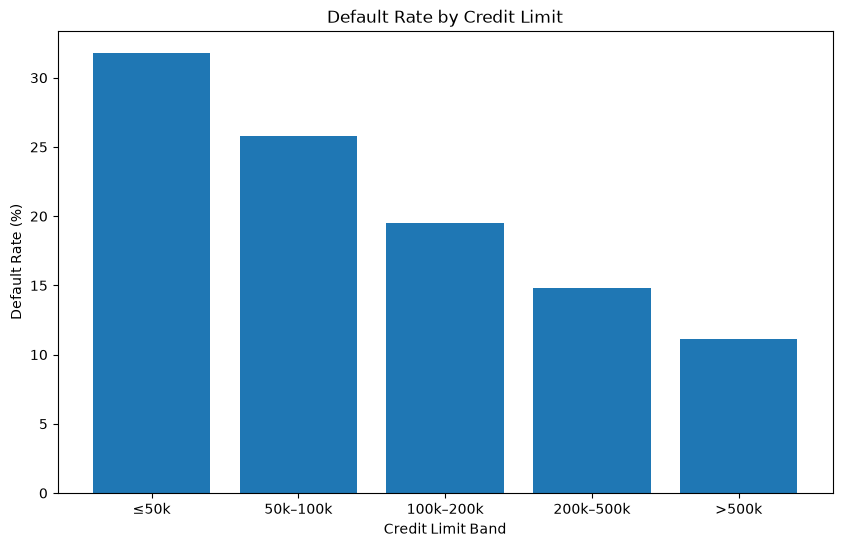

In [29]:
plt.figure(figsize=(10, 6))

plt.bar(
    credit_limit_risk.index.astype(str),
    credit_limit_risk["default_rate_%"]
)

plt.xlabel("Credit Limit Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Credit Limit")

plt.show()

### Credit Limit and Default Risk

A clear relationship can be observed between credit limit and default rate in this dataset.

Customers with credit limits of 50,000 or below had the highest default rate at approximately **31.8%**, compared with approximately **11.2%** among customers with credit limits above 500,000.

Overall, the observed default rate decreases as credit limits increase. This suggests that credit limit may contain useful information for identifying differences in customer credit risk.

However, this does not demonstrate that increasing a customer's credit limit would reduce their probability of default. Credit limits may themselves reflect other characteristics of a customer's financial position and previous credit assessment.

In [30]:
# Create age bands

df["AGE_BAND"] = pd.cut(
    df["AGE"],
    bins=[20, 29, 39, 49, 59, 69, 100],
    labels=[
        "20–29",
        "30–39",
        "40–49",
        "50–59",
        "60–69",
        "70+"
    ]
)

age_risk = (
    df.groupby("AGE_BAND", observed=True)["DEFAULT"]
      .agg(["count", "mean"])
)

age_risk["default_rate_%"] = age_risk["mean"] * 100

age_risk

,count,mean,default_rate_%
AGE_BAND,,,
20–29,9618,0.228426,22.842587
30–39,11238,0.202527,20.252714
40–49,6464,0.229734,22.973391
50–59,2341,0.248612,24.861170
60–69,314,0.283439,28.343949
70+,25,0.280000,28.000000


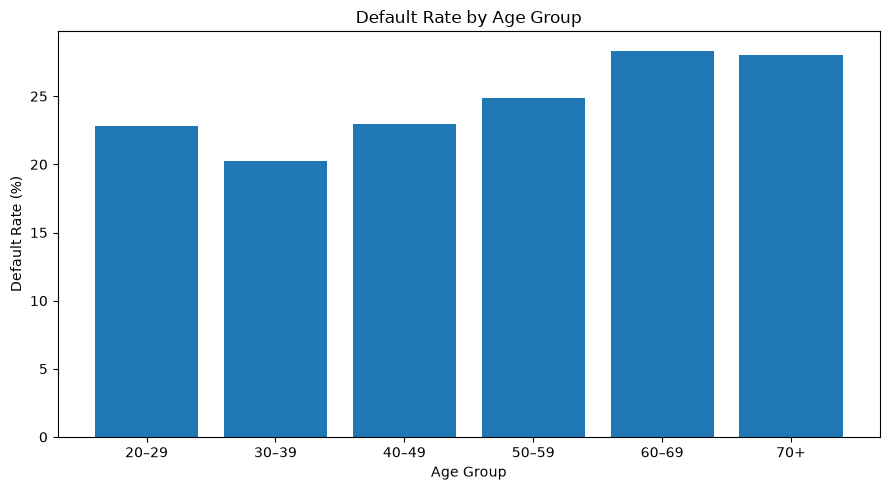

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    age_risk.index.astype(str),
    age_risk["default_rate_%"]
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### Age and Default Risk — Initial Finding

Default rates vary across age groups. Customers aged 30–39 had the lowest observed default rate at approximately 20.25%, while the rate generally increased among older age groups, reaching approximately 28.34% for customers aged 60–69.

The 70+ group also showed a relatively high default rate of 28%, although this group contained only 25 customers. Therefore, this result should be interpreted cautiously because the small sample size makes the estimate less reliable.

These findings suggest that age is associated with differences in default risk within this dataset. However, age alone should not be used to make conclusions about an individual's creditworthiness. Other financial and behavioural characteristics, particularly repayment history and credit utilisation, should be considered alongside it.

This analysis identifies an association and does not demonstrate that age causes differences in default risk.

## Payment Behaviour Analysis

Repayment behaviour is an important component of credit risk assessment. This section examines whether customers who make lower payments relative to their outstanding bill amounts show different default behaviour.

In [32]:
# Calculate payment-to-bill ratio for the most recent month

df["PAYMENT_RATIO"] = (
    df["PAY_AMT1"] / df["BILL_AMT1"].replace(0, float("nan"))
)

# Remove extreme ratios for this exploratory analysis
df["PAYMENT_RATIO_CAPPED"] = df["PAYMENT_RATIO"].clip(lower=0, upper=1)

# Create repayment ratio groups
df["PAYMENT_GROUP"] = pd.cut(
    df["PAYMENT_RATIO_CAPPED"],
    bins=[-0.01, 0, 0.25, 0.50, 0.75, 1.0],
    labels=[
        "No payment",
        "1–25%",
        "26–50%",
        "51–75%",
        "76–100%"
    ]
)

payment_risk = (
    df.groupby("PAYMENT_GROUP", observed=True)["DEFAULT"]
      .agg(["count", "mean"])
)

payment_risk["default_rate_%"] = payment_risk["mean"] * 100

payment_risk

,count,mean,default_rate_%
PAYMENT_GROUP,,,
No payment,4085,0.366952,36.695226
1–25%,16823,0.208524,20.852404
26–50%,1661,0.173390,17.338952
51–75%,884,0.130090,13.009050
76–100%,4539,0.152456,15.245649


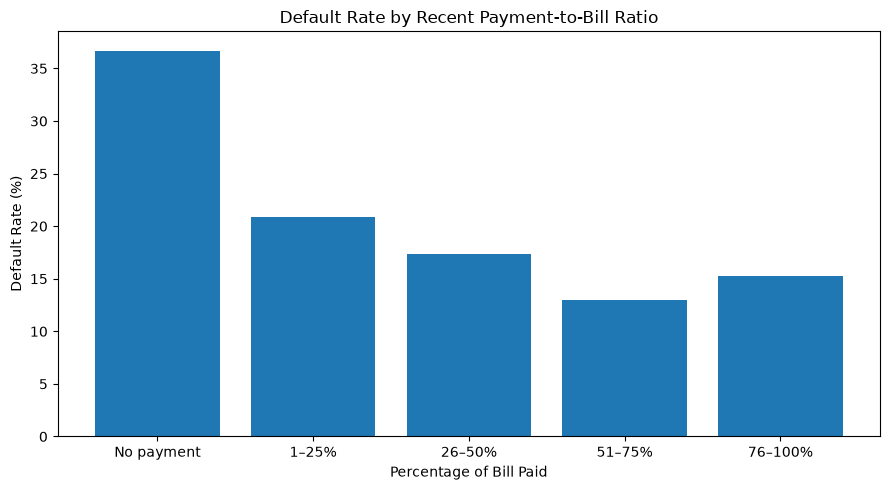

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    payment_risk.index.astype(str),
    payment_risk["default_rate_%"]
)

plt.title("Default Rate by Recent Payment-to-Bill Ratio")
plt.xlabel("Percentage of Bill Paid")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### Payment Behaviour and Default Risk — Initial Finding

The analysis indicates a strong association between recent repayment behaviour and subsequent default.

Customers who made no payment against their most recent bill had the highest observed default rate at approximately **36.70%**. In comparison, customers who paid between 51–75% of their bill had an observed default rate of approximately **13.01%**.

Overall, customers making larger payments relative to their outstanding bill tended to show lower default rates, although the relationship was not perfectly linear. The 76–100% group had a slightly higher default rate than the 51–75% group.

This suggests that recent payment behaviour may provide useful information when assessing credit risk. However, the relationship represents an association and does not demonstrate that lower repayments directly cause default. Other factors, including previous repayment status, credit limit and wider financial characteristics, should also be considered.

## Credit Utilisation Analysis

Credit utilisation measures the proportion of a customer's available credit that is currently being used. This analysis investigates whether customers with higher utilisation levels show higher observed default rates.


In [34]:
# Calculate most recent credit utilisation

df["UTILISATION"] = df["BILL_AMT1"] / df["LIMIT_BAL"]

# Prevent unusual negative bill values from distorting the grouping
df["UTILISATION_CAPPED"] = df["UTILISATION"].clip(lower=0, upper=1)

# Create utilisation bands
df["UTILISATION_BAND"] = pd.cut(
    df["UTILISATION_CAPPED"],
    bins=[-0.01, 0.25, 0.50, 0.75, 1.0],
    labels=[
        "0–25%",
        "26–50%",
        "51–75%",
        "76–100%"
    ]
)

utilisation_risk = (
    df.groupby("UTILISATION_BAND", observed=True)["DEFAULT"]
      .agg(["count", "mean"])
)

utilisation_risk["default_rate_%"] = utilisation_risk["mean"] * 100

utilisation_risk

,count,mean,default_rate_%
UTILISATION_BAND,,,
0–25%,14038,0.182790,18.278957
26–50%,3588,0.217391,21.739130
51–75%,3579,0.259570,25.956971
76–100%,8795,0.268448,26.844798


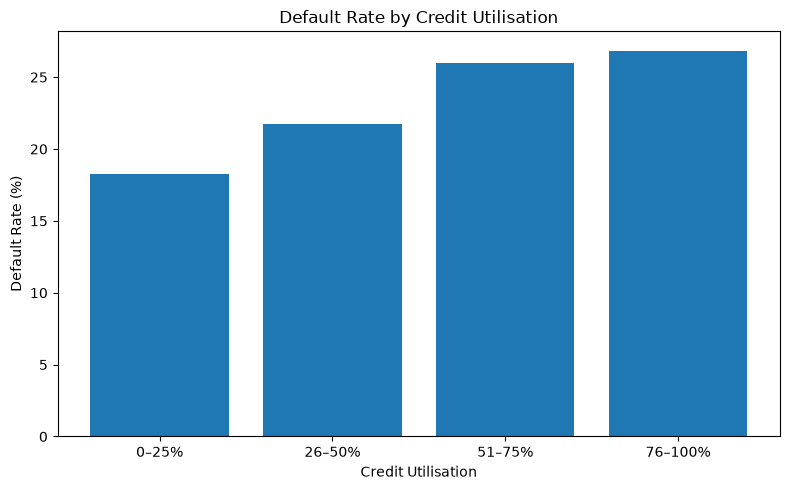

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    utilisation_risk.index.astype(str),
    utilisation_risk["default_rate_%"]
)

plt.title("Default Rate by Credit Utilisation")
plt.xlabel("Credit Utilisation")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

### Credit Utilisation and Default Risk — Initial Finding

The analysis shows a clear association between credit utilisation and observed default risk.

Customers using 0–25% of their available credit had the lowest observed default rate at approximately **18.28%**. The default rate increased across each utilisation band, reaching approximately **26.84%** among customers using 76–100% of their available credit.

This suggests that higher credit utilisation may be a useful indicator of increased credit risk. Customers using a large proportion of their available credit may have less remaining borrowing capacity and could potentially be under greater financial pressure.

However, this analysis identifies an association rather than a causal relationship. Credit utilisation should therefore be considered alongside repayment history, payment behaviour and other customer characteristics when assessing default risk.

## Data Understanding — Key Findings

The exploratory analysis identified several characteristics associated with credit-card default risk within the dataset.

### 1. Target Distribution
The dataset contains **30,000 customers**, of whom approximately **22.12% defaulted** in the following month. This creates a moderate class imbalance that should be considered when evaluating predictive models.

### 2. Repayment Status
Recent repayment behaviour showed a strong relationship with default. Customers experiencing payment delays generally had substantially higher observed default rates, suggesting that repayment history could be an important predictor of future default.

### 3. Credit Limit
Customers with lower credit limits showed higher observed default rates than customers with larger credit limits. However, credit limit should not be interpreted as directly causing default because it may reflect other aspects of a customer's financial position and previous credit assessment.

### 4. Age
Default rates differed across age groups. Customers aged 30–39 showed the lowest observed default rate, while higher rates were observed among some older groups. Age should not be considered independently when making credit decisions and requires careful treatment in responsible modelling.

### 5. Payment Behaviour
Customers who made no payment against their most recent bill had an observed default rate of approximately **36.70%**, considerably higher than customers making payments towards their balance. This suggests that recent payment behaviour contains useful information about credit risk.

### 6. Credit Utilisation
Default rates increased as customers used a larger proportion of their available credit. Customers with 0–25% utilisation had an observed default rate of approximately **18.28%**, compared with approximately **26.84%** for customers in the 76–100% utilisation group.

## Overall Conclusion

The exploratory analysis suggests that **repayment history, payment behaviour and credit utilisation** are particularly useful indicators of default risk.

These findings will inform the next stage of the project, where the data will be prepared for machine-learning modelling. The objective will not simply be to maximise predictive accuracy, but to develop an interpretable approach that can help explain which factors contribute to estimated credit risk.

The relationships identified in this notebook are associations within the dataset and should not be interpreted as evidence of causation.